# UIUC Enrollment Demographic Analysis (1968–2016)

## Project Overview

This project explores historical enrollment trends at the University of Illinois Urbana-Champaign (UIUC) from 1968 to 2016 using Python.

The analysis examines how the university's reported student demographic composition changed over time, focusing on African American, Asian American, Hispanic, Caucasian, and international student enrollment.

### Research Questions

1. How did UIUC's student demographic composition change between 1968 and 2016?
2. Which demographic groups experienced the largest changes in enrollment share?
3. How did the pace of demographic change vary across decades?
4. What data quality issues or inconsistencies exist in the historical enrollment records?

### Tools and Technologies

- **Python** — Data analysis
- **Pandas** — Data cleaning, aggregation, and calculations
- **Matplotlib** — Data visualization
- **Jupyter Notebook** — Interactive analysis
- **VS Code** — Development environment

### Project Scope

This project focuses on descriptive analysis of historical enrollment data. It identifies trends and changes in enrollment representation but does not attempt to establish the causes of those changes.

## Dataset Description

This project uses historical student enrollment data from the University of Illinois Urbana-Champaign (UIUC), covering fall semesters from 1968 through 2016.

The dataset contains enrollment records categorized by academic level and student demographics.

### Key Variables

- **Fall Term:** Academic year of enrollment.
- **Level:** Undergraduate, Graduate, or Professional.
- **Total:** Total student enrollment.
- **Demographic Categories:** African American, Asian American, Hispanic, Caucasian, International, Native American, Multiracial, Hawaiian/Pacific Islander, and Unknown.

### Data Preparation

The dataset required cleaning and validation before analysis, including:

- Converting enrollment values into numeric formats.
- Removing commas from numeric values.
- Aggregating enrollment counts by year.
- Calculating demographic percentages relative to total enrollment.
- Checking whether demographic totals matched reported enrollment totals.

Some historical records contained discrepancies, which are documented in the analysis.

### Limitations

Demographic reporting categories may have changed over time, potentially affecting comparisons across years. Additionally, the analysis identified unresolved enrollment discrepancies in 1989 and 2016.

In [5]:
## Import Libraries and Load Dataset

In [6]:
import pandas as pd

In [7]:
df = pd.read_csv("../data/Cycle 1, Trial Paper, OG data - Original.csv")

In [8]:
df.head()

,Fall Term,Level,Total,Unknown,Native American,African American,Asian American,Hispanic,Caucasian,International,...,Asian American.1,Hispanic.1,Caucasian.1,International.1,Hawaiian/ Pacific Isl.1,Multiracial.1,All African American.1,All Native American.1,All Hawaiian/ Pac Isl.1,All Asian.1
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016.0,***Campus total***,44880.0,1,35.0,2317,6633,3949,19721,10700,...,-6099.65,-7253.26,-8406.88,-9560.49,-10714.100,-11867.700,-13021.300,-14175.000,-15328.60,-16482.200
2,2016.0,Undergraduate,33467.0,0,22.0,1961,5867,3453,15467,5537,...,-4331.14,-5181.05,-6030.97,-6880.89,-7730.810,-8580.730,-9430.650,-10280.600,-11130.50,-11980.400
3,2016.0,Graduate,10428.0,1,12.0,326,694,444,3575,5097,...,-1596.08,-1872.13,-2148.18,-2424.23,-2700.280,-2976.330,-3252.380,-3528.440,-3804.49,-4080.540
4,2016.0,Professional,985.0,0,1.0,30,72,52,679,66,...,-172.431,-200.077,-227.723,-255.369,-283.015,-310.662,-338.308,-365.954,-393.60,-421.246


In [9]:
df.shape

(245, 38)

In [10]:
df.columns.tolist()

['Fall Term',
 'Level',
 'Total',
 'Unknown',
 'Native American',
 'African American',
 'Asian American',
 'Hispanic',
 'Caucasian',
 'International',
 'Hawaiian/ Pacific Isl',
 'Multiracial',
 'All African American',
 'All Native American',
 'All Hawaiian/ Pac Isl',
 'All Asian',
 'Unnamed: 16',
 'Unnamed: 17',
 'Unnamed: 18',
 'Unnamed: 19',
 'Unnamed: 20',
 'Unnamed: 21',
 'Fall Term.1',
 'Level.1',
 'Total.1',
 'Unknown.1',
 'Native American.1',
 'African American.1',
 'Asian American.1',
 'Hispanic.1',
 'Caucasian.1',
 'International.1',
 'Hawaiian/ Pacific Isl.1',
 'Multiracial.1',
 'All African American.1',
 'All Native American.1',
 'All Hawaiian/ Pac Isl.1',
 'All Asian.1']

In [11]:
df.iloc[:, :16].head(10)

,Fall Term,Level,Total,Unknown,Native American,African American,Asian American,Hispanic,Caucasian,International,Hawaiian/ Pacific Isl,Multiracial,All African American,All Native American,All Hawaiian/ Pac Isl,All Asian
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016.0,***Campus total***,44880.0,1,35.0,2317,6633,3949,19721,10700,27.0,1175.0,2786.0,374.0,154.0,7585.0
2,2016.0,Undergraduate,33467.0,0,22.0,1961,5867,3453,15467,5537,24.0,987.0,2344.0,292.0,138.0,6642.0
3,2016.0,Graduate,10428.0,1,12.0,326,694,444,3575,5097,3.0,170.0,403.0,77.0,14.0,855.0
4,2016.0,Professional,985.0,0,1.0,30,72,52,679,66,0.0,18.0,39.0,5.0,2.0,88.0
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2015.0,***Campus total***,44087.0,428,37.0,2167,6269,3592,20068,10381,30.0,1115.0,2612.0,355.0,151.0,7155.0
7,2015.0,Undergraduate,32878.0,231,21.0,1786,5571,3108,15695,5511,24.0,931.0,2138.0,267.0,131.0,6311.0
8,2015.0,Graduate,10245.0,80,16.0,349,637,431,3741,4819,5.0,167.0,432.0,84.0,17.0,769.0
9,2015.0,Professional,964.0,117,0.0,32,61,53,632,51,1.0,17.0,42.0,4.0,3.0,75.0


## Data Cleaning and Preparation

Before analyzing enrollment trends, the dataset was prepared to ensure that numerical values could be used in calculations.

The preparation process included:

1. Inspecting the dataset's structure and column names.
2. Converting enrollment counts from text to numeric values.
3. Handling missing or nonnumeric entries.
4. Aggregating enrollment counts by academic year.
5. Validating demographic totals against reported enrollment totals.

Data discrepancies were investigated separately to avoid drawing conclusions from potentially inconsistent records.

## Data Cleaning and Preparation

In [12]:
clean_df = df.iloc[:, :16].copy()

In [13]:
clean_df = clean_df.dropna(how="all")

In [14]:
clean_df.shape

(196, 16)

In [15]:
clean_df["Level"].unique()

<StringArray>
['***Campus total***', 'Undergraduate', 'Graduate', 'Professional']
Length: 4, dtype: str

In [16]:
clean_df = clean_df[clean_df["Level"] != "***Campus total***"]

In [17]:
clean_df["Level"].unique()

<StringArray>
['Undergraduate', 'Graduate', 'Professional']
Length: 3, dtype: str

In [18]:
clean_df["Fall Term"].unique()

array([2016., 2015., 2014., 2013., 2012., 2011., 2010., 2009., 2008.,
       2007., 2006., 2005., 2004., 2003., 2002., 2001., 2000., 1999.,
       1998., 1997., 1996., 1995., 1994., 1993., 1992., 1991., 1990.,
       1989., 1988., 1987., 1986., 1985., 1984., 1983., 1982., 1981.,
       1980., 1979., 1978., 1977., 1976., 1975., 1974., 1973., 1972.,
       1971., 1970., 1969., 1968.])

In [19]:
clean_df.isnull().sum()

Fall Term                  0
Level                      0
Total                      0
Unknown                    0
Native American            0
African American           0
Asian American             0
Hispanic                   0
Caucasian                  0
International              0
Hawaiian/ Pacific Isl    126
Multiracial              126
All African American     126
All Native American      126
All Hawaiian/ Pac Isl    138
All Asian                138
dtype: int64

In [20]:
clean_df[clean_df["Multiracial"].isnull()][["Fall Term", "Level", "Multiracial"]].head(10)

,Fall Term,Level,Multiracial
37,2009.0,Undergraduate,NaN
38,2009.0,Graduate,NaN
39,2009.0,Professional,NaN
42,2008.0,Undergraduate,NaN
43,2008.0,Graduate,NaN
44,2008.0,Professional,NaN
47,2007.0,Undergraduate,NaN
48,2007.0,Graduate,NaN
49,2007.0,Professional,NaN
52,2006.0,Undergraduate,NaN


In [21]:
clean_df[clean_df["Multiracial"].notnull()]["Fall Term"].min()

np.float64(2010.0)

In [22]:
clean_df["Fall Term"] = clean_df["Fall Term"].astype(int)

In [23]:
clean_df.head(10)

,Fall Term,Level,Total,Unknown,Native American,African American,Asian American,Hispanic,Caucasian,International,Hawaiian/ Pacific Isl,Multiracial,All African American,All Native American,All Hawaiian/ Pac Isl,All Asian
2,2016,Undergraduate,33467.0,0,22.0,1961,5867,3453,15467,5537,24.0,987.0,2344.0,292.0,138.0,6642.0
3,2016,Graduate,10428.0,1,12.0,326,694,444,3575,5097,3.0,170.0,403.0,77.0,14.0,855.0
4,2016,Professional,985.0,0,1.0,30,72,52,679,66,0.0,18.0,39.0,5.0,2.0,88.0
7,2015,Undergraduate,32878.0,231,21.0,1786,5571,3108,15695,5511,24.0,931.0,2138.0,267.0,131.0,6311.0
8,2015,Graduate,10245.0,80,16.0,349,637,431,3741,4819,5.0,167.0,432.0,84.0,17.0,769.0
9,2015,Professional,964.0,117,0.0,32,61,53,632,51,1.0,17.0,42.0,4.0,3.0,75.0
12,2014,Undergraduate,32579.0,255,18.0,1743,5148,2819,16368,5332,36.0,860.0,2081.0,243.0,138.0,5879.0
13,2014,Graduate,10037.0,153,17.0,341,654,431,3808,4484,8.0,141.0,416.0,81.0,17.0,784.0
14,2014,Professional,987.0,161,1.0,42,63,53,598,55,1.0,13.0,50.0,6.0,3.0,72.0
17,2013,Undergraduate,32294.0,182,18.0,1764,4833,2643,17010,4990,48.0,806.0,2070.0,239.0,NaN,NaN


In [24]:
clean_df.shape

(147, 16)

## Exploratory Data Analysis
## Total Enrollment by Year

In [25]:
yearly_enrollment = clean_df.groupby("Fall Term")["Total"].sum()
yearly_enrollment.head()

Fall Term
1968    31843.0
1969    32759.0
1970    34018.0
1971    32280.0
1972    33824.0
Name: Total, dtype: float64

In [26]:
yearly_enrollment.tail()

Fall Term
2012    42883.0
2013    43398.0
2014    43603.0
2015    44087.0
2016    44880.0
Name: Total, dtype: float64

In [27]:
import matplotlib.pyplot as plt

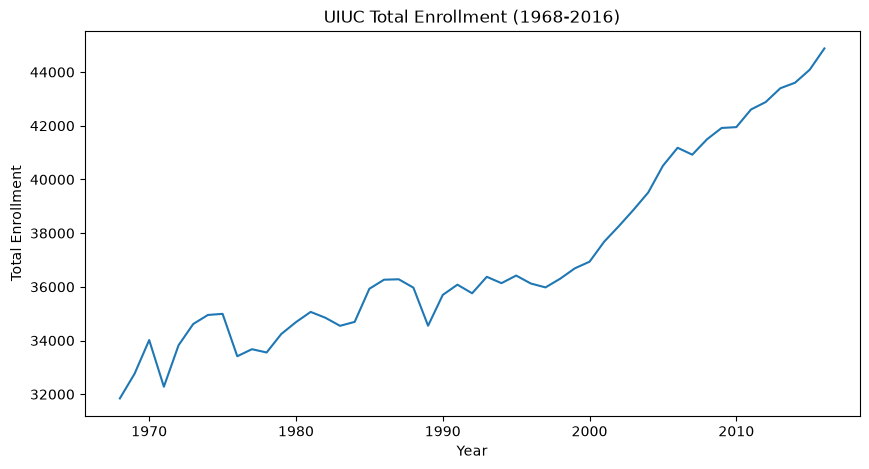

In [28]:
plt.figure(figsize=(10,5))
plt.plot(yearly_enrollment.index, yearly_enrollment.values)

plt.title("UIUC Total Enrollment (1968-2016)")
plt.xlabel("Year")
plt.ylabel("Total Enrollment")

plt.show()

In [29]:
start_enrollment = yearly_enrollment.loc[1968]
end_enrollment = yearly_enrollment.loc[2016]

growth_percent = ((end_enrollment - start_enrollment) / start_enrollment)*100
print(f"Total enrollment growth (1968–2016): {growth_percent:.2f}%")

Total enrollment growth (1968–2016): 40.94%


### Enrollment by Academic Level

In [30]:
level_enrollment = clean_df.pivot(
    index = "Fall Term",
    columns = "Level",
    values = "Total"
)

level_enrollment.head()

Level,Graduate,Professional,Undergraduate
Fall Term,,,
1968,8046.0,853.0,22944.0
1969,8462.0,866.0,23431.0
1970,8458.0,1002.0,24558.0
1971,8127.0,1048.0,23105.0
1972,8117.0,1013.0,24694.0


In [31]:
level_enrollment.tail()

Level,Graduate,Professional,Undergraduate
Fall Term,,,
2012,9881.0,1101.0,31901.0
2013,10080.0,1024.0,32294.0
2014,10037.0,987.0,32579.0
2015,10245.0,964.0,32878.0
2016,10428.0,985.0,33467.0


In [32]:
level_growth = ((level_enrollment.loc[2016] - level_enrollment.loc[1968])/level_enrollment.loc[1968])
level_growth

Level
Graduate         0.296048
Professional     0.154748
Undergraduate    0.458638
dtype: float64

In [33]:
level_growth = ((level_enrollment.loc[2016] - level_enrollment.loc[1968])/level_enrollment.loc[1968]*100)
level_growth

Level
Graduate         29.604773
Professional     15.474795
Undergraduate    45.863842
dtype: float64

## Enrollment Trends by Academic Level (1968-2016)

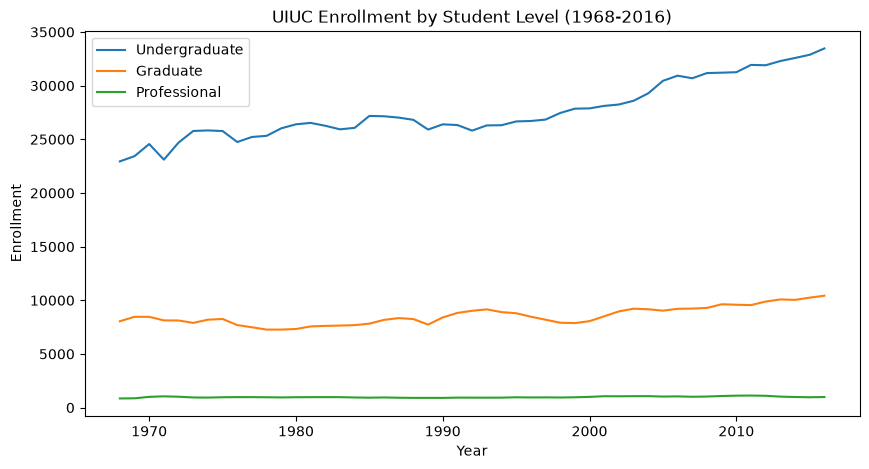

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(level_enrollment.index, level_enrollment["Undergraduate"], label="Undergraduate")
plt.plot(level_enrollment.index, level_enrollment["Graduate"], label="Graduate")
plt.plot(level_enrollment.index, level_enrollment["Professional"], label="Professional")

plt.title("UIUC Enrollment by Student Level (1968-2016)")
plt.xlabel("Year")
plt.ylabel("Enrollment")

plt.legend()

plt.show()

In [35]:
yearly_enrollment.idxmax()

np.int64(2016)

In [36]:
yearly_enrollment.max()

np.float64(44880.0)

In [37]:
yearly_enrollment.idxmin()

np.int64(1968)

In [38]:
yearly_enrollment.min()

np.float64(31843.0)

In [39]:
yearly_change = yearly_enrollment.pct_change()*100
yearly_change.head(10)

Fall Term
1968         NaN
1969    2.876613
1970    3.843219
1971   -5.109060
1972    4.783147
1973    2.341533
1974    0.973538
1975    0.117300
1976   -4.512202
1977    0.784079
Name: Total, dtype: float64

In [40]:
yearly_change.idxmax()

np.int64(1972)

In [41]:
yearly_change.max()

np.float64(4.783147459727388)

In [42]:
yearly_change.idxmin()

np.int64(1971)

In [43]:
yearly_change.min()

np.float64(-5.109059909459701)

In [44]:
clean_df.count()

Fall Term                147
Level                    147
Total                    147
Unknown                  147
Native American          147
African American         147
Asian American           147
Hispanic                 147
Caucasian                147
International            147
Hawaiian/ Pacific Isl     21
Multiracial               21
All African American      21
All Native American       21
All Hawaiian/ Pac Isl      9
All Asian                  9
dtype: int64

In [45]:
demographic_cols = [
    "African American", 
    "Asian American",
    "Hispanic",
    "Caucasian", 
    "International" 
]

demographics = clean_df.groupby("Fall Term")[demographic_cols].sum()
demographics.head()

,African American,Asian American,Hispanic,Caucasian,International
Fall Term,,,,,
1968,70114011,310723,103336,"18,9995,614734","1391,0134"
1969,78322121,307714,108487,"19,3685,525741","931,2131"
1970,94326741,330655,121527,"22,3066,134912","851,2561"
1971,"1,03928039",292665,96409,"20,7695,720958","841,0530"
1972,"1,09430141",284745,104338,"21,9285,875921","1421,0030"


In [46]:
clean_df[demographic_cols].dtypes

African American    str
Asian American      str
Hispanic            str
Caucasian           str
International       str
dtype: object

In [47]:
for col in demographic_cols:
    clean_df[col] = pd.to_numeric(
        clean_df[col].str.replace(",", "", regex=False),
        errors="coerce"
    )
clean_df[demographic_cols].dtypes

African American    int64
Asian American      int64
Hispanic            int64
Caucasian           int64
International       int64
dtype: object

In [48]:
clean_df[demographic_cols].isnull().sum()

African American    0
Asian American      0
Hispanic            0
Caucasian           0
International       0
dtype: int64

### Demographic Enrollment Trends

In [49]:
demographics = clean_df.groupby("Fall Term")[demographic_cols].sum()
demographics.head()

,African American,Asian American,Hispanic,Caucasian,International
Fall Term,,,,,
1968,852,385,142,25347,1156
1969,1025,382,163,25634,1307
1970,1251,400,180,29352,1342
1971,1358,363,145,27447,1137
1972,1436,363,145,28724,1145


#### Comparing Selected Demographics with Total Enrollment

In [50]:
comparison = pd.DataFrame({
    "Total Enrollment" : yearly_enrollment,
    "Selected Demographics" : demographics.sum(axis=1)
})
comparison["Difference"] = (
comparison["Total Enrollment"] - comparison["Selected Demographics"]
)
comparison.head()

,Total Enrollment,Selected Demographics,Difference
Fall Term,,,
1968,31843.0,27882,3961.0
1969,32759.0,28511,4248.0
1970,34018.0,32525,1493.0
1971,32280.0,30450,1830.0
1972,33824.0,31813,2011.0


In [51]:
unknown_by_year = clean_df.groupby("Fall Term")["Unknown"].sum()
comparison["Unknown"] = unknown_by_year
comparison[["Difference", "Unknown"]].head(10)


,Difference,Unknown
Fall Term,,
1968,3961.0,"2,1311,12481"
1969,4248.0,"2,3761,33681"
1970,1493.0,49961926
1971,1830.0,65592632
1972,2011.0,"1,05580335"
1973,1421.0,60769858
1974,1978.0,939766244
1975,1128.0,63639474
1976,782.0,40227540


In [52]:
clean_df["Unknown"] = pd.to_numeric(
    clean_df["Unknown"].str.replace(",", "", regex=False),
    errors="coerce"
)

clean_df[["Unknown"]].dtypes

Unknown    int64
dtype: object

In [53]:
unknown_by_year = clean_df.groupby("Fall Term")["Unknown"].sum()
comparison["Unknown"] = unknown_by_year
comparison[["Difference", "Unknown"]].head(10)

,Difference,Unknown
Fall Term,,
1968,3961.0,3336
1969,4248.0,3793
1970,1493.0,1144
1971,1830.0,1613
1972,2011.0,1893
1973,1421.0,1363
1974,1978.0,1949
1975,1128.0,1104
1976,782.0,717


In [54]:
clean_df["Native American"] = pd.to_numeric(
    clean_df["Native American"].astype(str).str.replace(",", "", regex=False), 
    errors = "coerce"
)

native_by_year = clean_df.groupby("Fall Term")["Native American"].sum()

comparison["Native American"] = native_by_year

comparison["Remaining"] = (
    comparison["Difference"]- comparison["Unknown"]-comparison["Native American"]
    

)

comparison[["Difference", "Unknown", "Native American", "Remaining"]].head(10)

,Difference,Unknown,Native American,Remaining
Fall Term,,,,
1968,3961.0,3336,625.0,0.0
1969,4248.0,3793,455.0,0.0
1970,1493.0,1144,349.0,0.0
1971,1830.0,1613,217.0,0.0
1972,2011.0,1893,118.0,0.0
1973,1421.0,1363,58.0,0.0
1974,1978.0,1949,29.0,0.0
1975,1128.0,1104,24.0,0.0
1976,782.0,717,65.0,0.0


In [55]:
comparison[comparison["Remaining"] !=0]

,Total Enrollment,Selected Demographics,Difference,Unknown,Native American,Remaining
Fall Term,,,,,,
1989,34551.0,34445,106.0,468,59.0,-421.0
2010,41949.0,40760,1189.0,386,57.0,746.0
2011,42606.0,41320,1286.0,376,57.0,853.0
2012,42883.0,41571,1312.0,342,47.0,923.0
2013,43398.0,41959,1439.0,392,35.0,1012.0
2014,43603.0,41939,1664.0,569,36.0,1059.0
2015,44087.0,42477,1610.0,428,37.0,1145.0
2016,44880.0,43320,1560.0,1,35.0,1524.0


In [56]:
cols = ["Multiracial", "Hawaiian/ Pacific Isl"]

for col in cols:
    clean_df[col] = pd.to_numeric(
        
        clean_df[col].astype(str).str.replace(",", "", regex=False), 
        errors = "coerce"
    )
clean_df.groupby("Fall Term")[cols].sum(min_count=1).loc[2010:2016]

,Multiracial,Hawaiian/ Pacific Isl
Fall Term,,
2010,687.0,59.0
2011,794.0,59.0
2012,862.0,61.0
2013,957.0,55.0
2014,1014.0,45.0
2015,1115.0,30.0
2016,1175.0,27.0


In [57]:
additional_by_year = clean_df.groupby("Fall Term")[cols].sum(min_count=1)

comparison["Multiracial"] = additional_by_year["Multiracial"]
comparison["Hawaiian/Pacific Isl"] = additional_by_year["Hawaiian/ Pacific Isl"]

comparison["Final Difference"] = (
    comparison["Remaining"]-comparison["Multiracial"]-comparison["Hawaiian/Pacific Isl"]
)

comparison.loc[2010:2016, ["Remaining", "Multiracial", "Hawaiian/Pacific Isl", "Final Difference"]]

,Remaining,Multiracial,Hawaiian/Pacific Isl,Final Difference
Fall Term,,,,
2010,746.0,687.0,59.0,0.0
2011,853.0,794.0,59.0,0.0
2012,923.0,862.0,61.0,0.0
2013,1012.0,957.0,55.0,0.0
2014,1059.0,1014.0,45.0,0.0
2015,1145.0,1115.0,30.0,0.0
2016,1524.0,1175.0,27.0,322.0


In [58]:
clean_df.columns.tolist()

['Fall Term',
 'Level',
 'Total',
 'Unknown',
 'Native American',
 'African American',
 'Asian American',
 'Hispanic',
 'Caucasian',
 'International',
 'Hawaiian/ Pacific Isl',
 'Multiracial',
 'All African American',
 'All Native American',
 'All Hawaiian/ Pac Isl',
 'All Asian']

In [59]:
all_cols = [
    "All African American", 
    "All Native American",
    "All Hawaiian/ Pac Isl", 
    "All Asian"
]

clean_df.loc[
    clean_df["Fall Term"] == 2016, 
    ["Fall Term", "Level", "Total"] + all_cols
]



,Fall Term,Level,Total,All African American,All Native American,All Hawaiian/ Pac Isl,All Asian
2,2016,Undergraduate,33467.0,2344.0,292.0,138.0,6642.0
3,2016,Graduate,10428.0,403.0,77.0,14.0,855.0
4,2016,Professional,985.0,39.0,5.0,2.0,88.0


In [60]:
data_2016 = clean_df[clean_df["Fall Term"] == 2016].copy()

categories = (
    demographic_cols + ["Unknown", "Native American", "Multiracial", "Hawaiian/ Pacific Isl"]
)

data_2016["Demographic Sum"] = data_2016[categories].sum(axis=1)
data_2016["Difference"] = (
    data_2016["Total"] - data_2016["Demographic Sum"]
)

data_2016[["Level", "Total", "Demographic Sum", "Difference"]]

,Level,Total,Demographic Sum,Difference
2,Undergraduate,33467.0,33318.0,149.0
3,Graduate,10428.0,10322.0,106.0
4,Professional,985.0,918.0,67.0


In [61]:
categories = demographic_cols + [
    "Unknown", 
    "Native American", 
    "Multiracial", 
    "Hawaiian/ Pacific Isl"
]

clean_df["Demographic Sum"] = clean_df[categories].sum(axis=1)

clean_df["Difference"] = (
    clean_df["Total"] - clean_df["Demographic Sum"]
)

yearly_discrepancy = clean_df.groupby("Fall Term")["Difference"].sum()
yearly_discrepancy[yearly_discrepancy != 0]

Fall Term
1989   -421.0
2016    322.0
Name: Difference, dtype: float64

## Data Visualizations
## Demographic Enrollment Share Over Time

## Demographic Enrollment Counts (1968-2016)
## Key Observations
## Interpretation

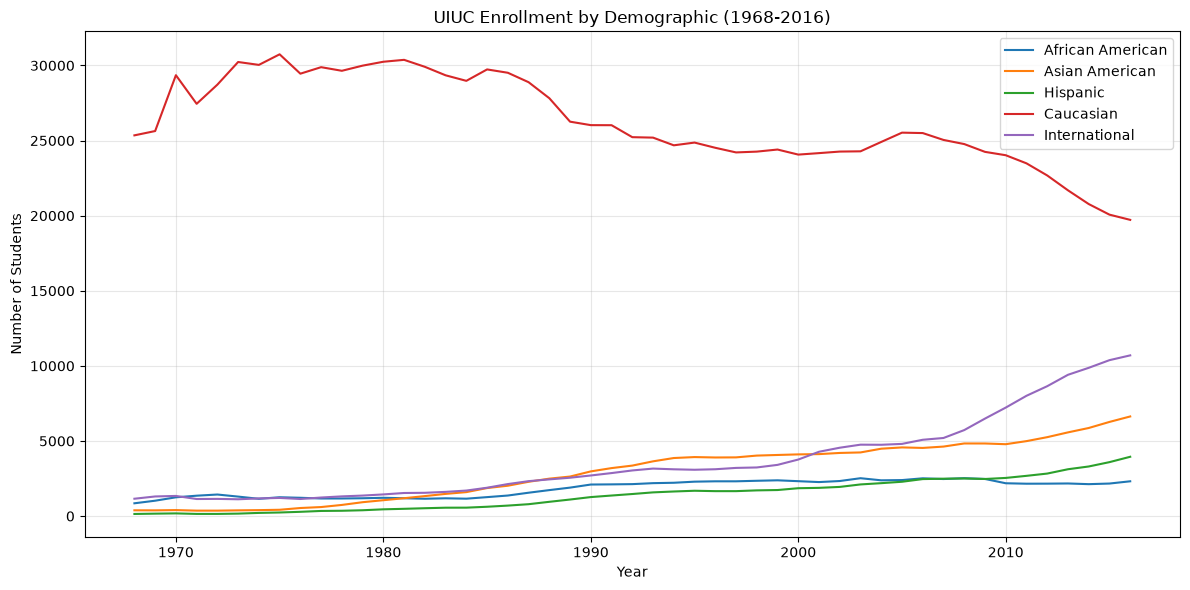

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

for col in demographic_cols:
    plt.plot(
        demographics.index, demographics[col], label=col
    )

plt.title("UIUC Enrollment by Demographic (1968-2016)")
plt.xlabel("Year")
plt.ylabel("Number of Students")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

### Demographic Enrollment Percentages

In [63]:
demographic_percent = demographics.div(yearly_enrollment, axis=0)*100
demographic_percent.loc[[1968, 1980, 2000, 2016]].round(2)

,African American,Asian American,Hispanic,Caucasian,International
Fall Term,,,,,
1968,2.68,1.21,0.45,79.60,3.63
1980,3.51,3.05,1.30,87.20,4.16
2000,6.29,11.12,5.02,65.16,10.19
2016,5.16,14.78,8.80,43.94,23.84


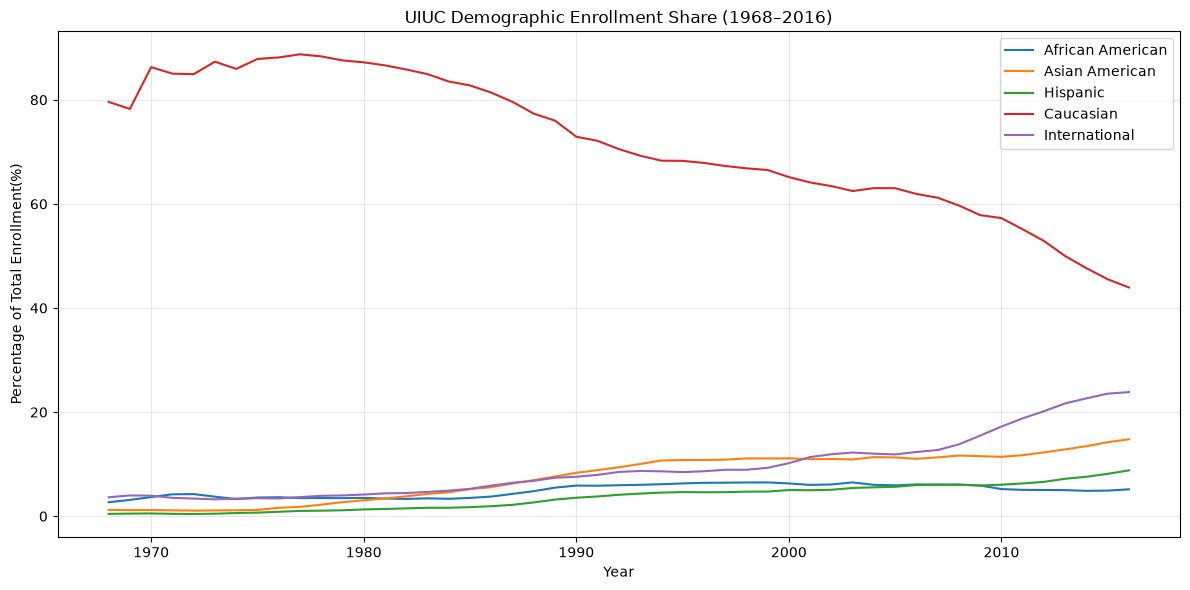

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for col in demographic_cols:
    plt.plot(
        demographic_percent.index, demographic_percent[col], label=col
    )

plt.title("UIUC Demographic Enrollment Share (1968–2016)")
plt.xlabel("Year")
plt.ylabel("Percentage of Total Enrollment(%)")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

In [65]:
change = (
    demographic_percent.loc[2016] - demographic_percent.loc[1968]
)

change = change.sort_values(ascending=False)
print("Change in Enrollment Share (1968-2016)")
print(change.round(2))

Change in Enrollment Share (1968-2016)
International       20.21
Asian American      13.57
Hispanic             8.35
African American     2.49
Caucasian          -35.66
dtype: float64


### Change in Demographic Enrollment Share (1968–2016)

This horizontal bar chart compares the change in each demographic group's percentage of total university enrollment between 1968 and 2016.

Changes are measured in **percentage points**, rather than percentage growth, to show how each group's representation shifted over time.

The results indicate that international and Asian American students experienced the largest increases in enrollment share, while Caucasian students experienced the largest decrease.

These findings describe changes in enrollment representation but do not establish the causes of those changes.

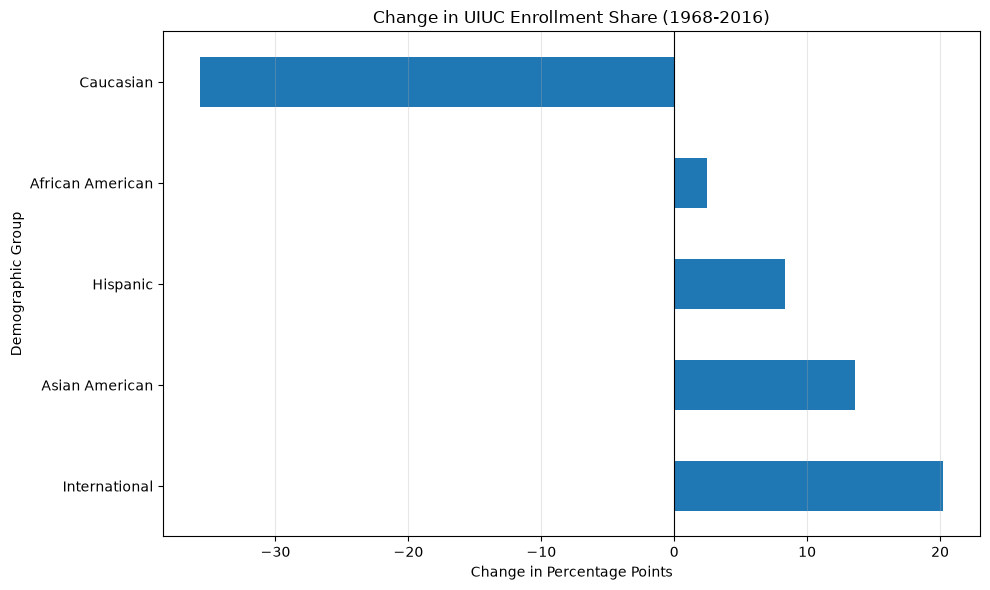

In [66]:
plt.figure(figsize=(10, 6))

change.plot(kind="barh")
plt.title("Change in UIUC Enrollment Share (1968-2016)")
plt.xlabel("Change in Percentage Points")
plt.ylabel("Demographic Group")
plt.axvline(0,color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [67]:
selected_years = [1970, 1980, 1990, 2000, 2010, 2016]
decade_percent = demographic_percent.loc[selected_years]
decade_percent.round(2)


,African American,Asian American,Hispanic,Caucasian,International
Fall Term,,,,,
1970,3.68,1.18,0.53,86.28,3.94
1980,3.51,3.05,1.30,87.20,4.16
1990,5.89,8.34,3.55,72.91,7.57
2000,6.29,11.12,5.02,65.16,10.19
2010,5.21,11.41,6.06,57.27,17.22
2016,5.16,14.78,8.80,43.94,23.84


In [68]:
decade_change = decade_percent.diff()
decade_change = decade_change.dropna()
decade_change.round(2)

,African American,Asian American,Hispanic,Caucasian,International
Fall Term,,,,,
1980,-0.16,1.87,0.77,0.92,0.22
1990,2.37,5.29,2.25,-14.30,3.41
2000,0.41,2.79,1.48,-7.75,2.62
2010,-1.08,0.29,1.03,-7.89,7.03
2016,-0.05,3.37,2.74,-13.33,6.62


In [69]:
period_lengths = [10,10,10,10,6]
annual_change = decade_change.div(
    period_lengths,axis=0
)
annual_change.round(2)

,African American,Asian American,Hispanic,Caucasian,International
Fall Term,,,,,
1980,-0.02,0.19,0.08,0.09,0.02
1990,0.24,0.53,0.22,-1.43,0.34
2000,0.04,0.28,0.15,-0.78,0.26
2010,-0.11,0.03,0.10,-0.79,0.70
2016,-0.01,0.56,0.46,-2.22,1.10


### Average Annual Change in Demographic Enrollment Share

This visualization compares the average annual change in enrollment share across five time periods between 1968 and 2016.

The analysis divides the total percentage-point change during each period by the number of years in that period.

The resulting values represent the average annual change in percentage points, allowing comparisons between periods of different lengths.

**Key Observations:**

- International enrollment share increased most rapidly during 2010–2016, averaging approximately 1.10 percentage points per year.
- Asian American enrollment share increased by approximately 0.56 percentage points per year during 2010–2016.
- Hispanic enrollment share increased by approximately 0.46 percentage points per year during 2010–2016.
- Caucasian enrollment share declined by approximately 2.22 percentage points per year during 2010–2016.
- African American enrollment share remained relatively stable during 2010–2016, with a slight average annual decrease of 0.01 percentage points.

These values describe average changes between period endpoints rather than the exact change in every individual year.

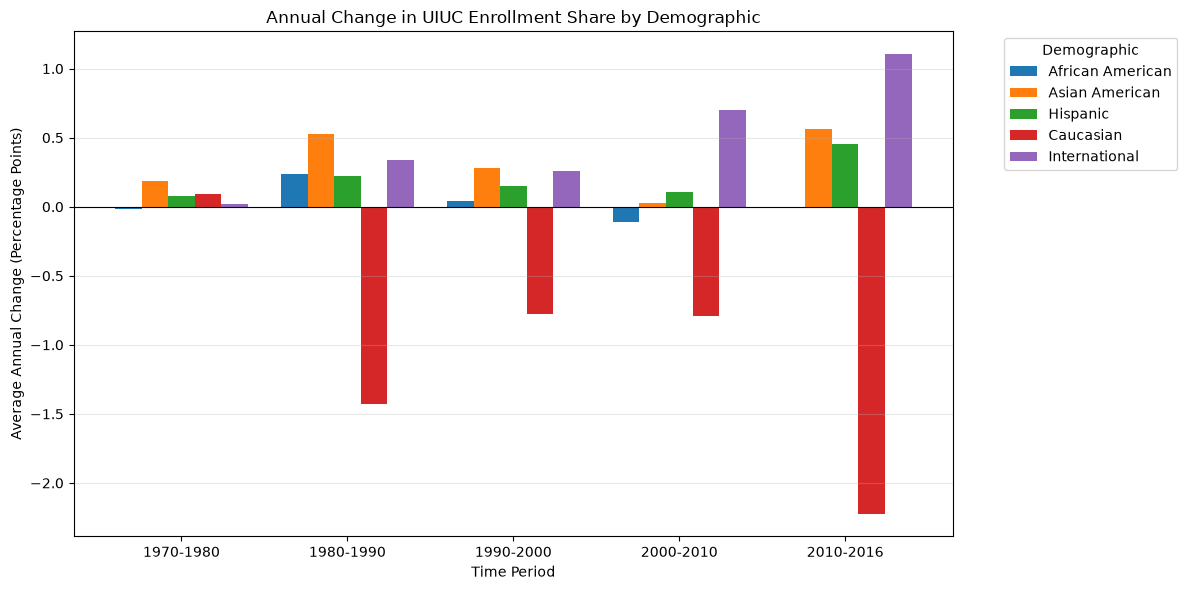

In [70]:
import matplotlib.pyplot as plt

annual_change.index = [
    "1970-1980",
    "1980-1990",
    "1990-2000",
    "2000-2010",
    "2010-2016"
]

annual_change.plot(
    kind="bar",
    figsize=(12,6),
    width=0.8
)

plt.title("Annual Change in UIUC Enrollment Share by Demographic")
plt.xlabel("Time Period")
plt.ylabel("Average Annual Change (Percentage Points)")
plt.axhline(0, color="black", linewidth=0.8)
plt.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.legend(title="Demographic", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Key Findings

### 1. Changes in Student Demographics (1968–2016)

The demographic composition of UIUC enrollment changed substantially between 1968 and 2016.

- **Caucasian students:** Enrollment share decreased from 79.60% to 43.94%, a decline of 35.66 percentage points.
- **International students:** Enrollment share increased from 3.63% to 23.84%, a gain of 20.21 percentage points.
- **Asian American students:** Enrollment share increased from 1.21% to 14.78%, a gain of 13.57 percentage points.
- **Hispanic students:** Enrollment share increased from 0.45% to 8.80%, a gain of 8.35 percentage points.
- **African American students:** Enrollment share increased from 2.68% to 5.16%, a gain of 2.49 percentage points.

### 2. Changes Across Time Periods

The pace of demographic change was not consistent across the entire study period. Between 2010 and 2016, international enrollment share increased by approximately 1.10 percentage points per year, while Caucasian enrollment share decreased by approximately 2.22 percentage points per year.

### 3. Data Quality and Limitations

Enrollment totals were compared against the sum of reported demographic categories. Most years reconciled, but discrepancies remained in 1989 (-421 students) and 2016 (+322 students). These discrepancies should be investigated before interpreting the dataset as fully reconciled.

### 4. Conclusion

The analysis shows substantial changes in UIUC's reported student demographic composition from 1968 to 2016. The largest changes among the five categories analyzed were a decline in the Caucasian enrollment share and an increase in the international enrollment share. These results describe historical enrollment patterns but do not establish the causes of those changes.